# 15. Fitting counts: maximum likelihood

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 6, 7 and 14

**Reading:** Bevington & Robinson, ch. 10 · Cowan, *Statistical Data
Analysis*, ch. 6–7 · James, *Statistical Methods in Experimental Physics*

Least squares is maximum likelihood for data with *normal* errors of *known*
standard deviation (Section 7.3). Histograms and spectra break both
conditions: the counts are Poisson-distributed, and the standard deviation
of a count is not known in advance but depends on the very quantity being
fitted. The usual workarounds, taking $\sigma_i^2 = n_i$ from the data or
$\sigma_i^2 = \mu_i$ from the model, bias the result when the counts are
small. This chapter quantifies the bias, shows how the Poisson likelihood
removes it, and treats two related questions: how to test goodness of fit
with few counts, and how to fit individual events without binning them at
all.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(115)

## 15.1 Three ways to fit a histogram

Let $n_i$ be the count in bin $i$ and $\mu_i(\mathbf p)$ its expected value
under the model. Three objective functions are in common use.

* **Neyman's $\chi^2$**, $\sum_i (n_i - \mu_i)^2/n_i$: the weights come from
  the observed counts. Empty bins must be given some arbitrary weight
  (here $\sigma_i^2 = 1$).
* **Pearson's $\chi^2$**, $\sum_i (n_i - \mu_i)^2/\mu_i$: the weights come from
  the model and change during the fit.
* The **Poisson likelihood**, $L = \prod_i \mu_i^{n_i} e^{-\mu_i}/n_i!$, best
  used in the form of the likelihood-ratio statistic of Baker and Cousins
  (1984),

$$ \chi^2_\lambda = 2\sum_i \left[ \mu_i - n_i + n_i \ln\frac{n_i}{\mu_i} \right] , $$

  which differs from $-2\ln L$ only by a constant, so minimising it gives the
  maximum-likelihood estimate. (A term with $n_i = 0$ contributes $2\mu_i$.)

The simplest case shows the problem: fitting a constant level $\mu$ to $k$
bins. Setting the derivatives to zero gives closed forms: Neyman's $\chi^2$
gives the *harmonic* mean of the counts, Pearson's the root-mean-square,
and the likelihood the ordinary mean. Since the harmonic mean is never
larger than the arithmetic mean and the root-mean-square never smaller, the
first is biased low and the second high.

In [2]:
mus = np.array([1, 2, 3, 5, 10, 20, 50, 100])
bias = {"Neyman": [], "Pearson": [], "likelihood": []}
for mu in mus:
    n = rng.poisson(mu, (20000, 20))                          # 20000 histograms of 20 bins
    bias["Neyman"].append(np.mean(20 / np.sum(1 / np.maximum(n, 1), axis=1)) - mu)
    bias["Pearson"].append(np.mean(np.sqrt(np.mean(n**2, axis=1))) - mu)
    bias["likelihood"].append(np.mean(n.mean(axis=1)) - mu)
print("true level   bias of the fitted level (counts per bin)")
print("             Neyman   Pearson   likelihood")
for i, mu in enumerate(mus):
    print(f"   {mu:4d}      {bias['Neyman'][i]:+6.2f}    {bias['Pearson'][i]:+6.2f}     {bias['likelihood'][i]:+6.3f}")

true level   bias of the fitted level (counts per bin)
             Neyman   Pearson   likelihood
      1       +0.18     +0.39     +0.000
      2       -0.40     +0.43     +0.003
      3       -0.78     +0.44     +0.004
      5       -1.10     +0.45     +0.003
     10       -1.07     +0.47     +0.003
     20       -1.00     +0.48     +0.006
     50       -0.96     +0.49     +0.014
    100       -0.94     +0.50     +0.028


For moderate and large counts, Neyman's fit is too low by about one count
per bin and Pearson's too high by about half a count per bin, *however
large the counts are*. In relative terms the bias fades as $1/\mu$, but it
never fades relative to the statistical uncertainty of a large histogram:
with 20 bins of 100 counts, the uncertainty of the level is
$\sqrt{100/20} = 2.2$ counts, and Neyman's bias is almost half of that. At one
count per bin Neyman's fit turns positive, an artefact of the arbitrary
weight given to empty bins. The likelihood fit is unbiased throughout.

**A peak on a background.** The same happens in a realistic fit. The next
cell generates 2000 histograms of 40 bins, each containing a Gaussian peak
of 120 events on a flat background of 3 counts per bin, and fits each with
all three methods. A least-squares routine can minimise $\chi^2_\lambda$ if
each term is written as the square of a signed **deviance residual**,
$d_i = \mathrm{sign}(n_i - \mu_i)\sqrt{2[\mu_i - n_i + n_i\ln(n_i/\mu_i)]}$.
The uncertainties of the likelihood fit come from the inverse of the Fisher
information, $\sum_i (\partial\mu_i/\partial p_k)(\partial\mu_i/\partial p_l)/\mu_i$.

In [3]:
edges = np.arange(0, 41)

def mu_model(p):
    B, S, x0, w = p                     # background per bin, peak events, centre, width
    return B + S * np.diff(stats.norm.cdf(edges, x0, w))

p_true = np.array([3.0, 120.0, 20.3, 2.0])
pnames = ["background B", "peak events S", "centre x0", "width w"]

def residuals(kind, n):
    if kind == "Neyman":
        return lambda p: (n - mu_model(p)) / np.sqrt(np.maximum(n, 1))
    if kind == "Pearson":
        return lambda p: (n - mu_model(p)) / np.sqrt(np.maximum(mu_model(p), 1e-9))
    def deviance(p):
        m = np.maximum(mu_model(p), 1e-12)
        d = 2 * (m - n + np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / m), 0))
        return np.sign(n - m) * np.sqrt(np.maximum(d, 0))
    return deviance

def fisher_cov(p):
    m = mu_model(p)
    J = np.empty((m.size, p.size))
    for k in range(p.size):
        h = 1e-5 * max(1.0, abs(p[k])); dp = np.zeros(p.size); dp[k] = h
        J[:, k] = (mu_model(p + dp) - mu_model(p - dp)) / (2 * h)
    return np.linalg.inv(J.T @ (J / m[:, None]))

kinds = ["Neyman", "Pearson", "likelihood"]
est = {k: [] for k in kinds}
inside = []
gof = {"Pearson at ML": [], "chi2_lambda": []}
for i in range(2000):
    n = rng.poisson(mu_model(p_true))
    if i == 0:
        n_example = n
    for k in kinds:
        r = residuals(k, n)
        p = optimize.least_squares(r, p_true, method="lm").x
        est[k].append(p)
        if k == "likelihood":
            inside.append(np.abs(p - p_true) < np.sqrt(np.diag(fisher_cov(p))))
            m = mu_model(p)
            gof["Pearson at ML"].append(np.sum((n - m)**2 / m))
            gof["chi2_lambda"].append(np.sum(r(p)**2))
print("mean relative bias over 2000 histograms:")
print("                  " + "  ".join(f"{nm:>14s}" for nm in pnames))
for k in kinds:
    a = np.array(est[k])
    print(f"   {k:12s}  " + "  ".join(f"{b:+14.1%}" for b in (a.mean(axis=0) - p_true) / p_true))
sd = np.array(est["likelihood"]).std(axis=0)
print("   (scatter of the likelihood estimates: " + ", ".join(f"{v / t:.0%}" for v, t in zip(sd, p_true)) + " of the true values)")
print("likelihood fit, fraction within ±1 sigma: " + ", ".join(f"{c:.2f}" for c in np.mean(inside, axis=0)))

mean relative bias over 2000 histograms:
                    background B   peak events S       centre x0         width w
   Neyman                -30.8%           +2.3%           +0.0%           -0.0%
   Pearson               +14.7%           -0.3%           +0.0%           -1.0%
   likelihood             -0.2%           +0.6%           +0.0%           -0.5%
   (scatter of the likelihood estimates: 11%, 11%, 1%, 11% of the true values)
likelihood fit, fraction within ±1 sigma: 0.69, 0.68, 0.65, 0.67


Both $\chi^2$ fits get the peak right but the background wrong: Neyman's by
about $-30\,\%$ and Pearson's by about $+15\,\%$, that is by $-0.9$ and
$+0.4$ counts per bin. The scatter of the background estimate from one
histogram is only about 0.3 counts per bin, so these are biases of three
and one and a half standard uncertainties, yet nothing in a single fit
reveals them: the fitted curves look equally good. The peak survives because it
sits in bins with many
counts; the background, spread over many bins of a few counts, takes the
whole bias. Any quantity that depends on the background level, such as a
peak-to-background ratio or a detection limit, inherits it. The likelihood
fit is unbiased, and its Fisher-information uncertainties cover close to
68 %.

## 15.2 Goodness of fit with few counts

After a likelihood fit, $\chi^2_\lambda$ at the minimum is the natural
goodness-of-fit statistic: as a likelihood ratio, it follows the $\chi^2$
distribution with $k - m$ degrees of freedom asymptotically, for many counts
per bin. How quickly is that reached? For a single bin with known $\mu$,
the expected contribution to Pearson's statistic is exactly 1, but its
variance is $2 + 1/\mu$ instead of 2; the contribution to $\chi^2_\lambda$
has a mean that differs from 1. The cell computes both exactly and then
checks the two statistics at the minimum of the 2000 fits above, with 36
degrees of freedom.

In [4]:
mu_grid = np.logspace(-1, 2, 60)
moments = {"Pearson": [], "lambda": []}
for mu in mu_grid:
    n = np.arange(0, int(mu + 15 * np.sqrt(mu) + 30))
    w = stats.poisson.pmf(n, mu)
    dev = 2 * (mu - n + np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / mu), 0))
    pea = (n - mu)**2 / mu
    moments["lambda"].append(((w * dev).sum(), (w * dev**2).sum() - (w * dev).sum()**2))
    moments["Pearson"].append(((w * pea).sum(), (w * pea**2).sum() - (w * pea).sum()**2))
moments = {k: np.array(v) for k, v in moments.items()}
for mu in (0.3, 1, 3, 10):
    j = np.argmin(np.abs(mu_grid - mu))
    print(f"mu = {mu_grid[j]:5.2f}:  chi2_lambda term mean {moments['lambda'][j, 0]:.3f}, var {moments['lambda'][j, 1]:.2f};"
          f"   Pearson term mean {moments['Pearson'][j, 0]:.3f}, var {moments['Pearson'][j, 1]:.2f}")
dof = edges.size - 1 - 4
crit = stats.chi2.ppf(0.95, dof)
for k, v in gof.items():
    v = np.array(v)
    print(f"{k:14s} at the minimum: mean {v.mean():.1f} (dof {dof}), rejected at the nominal 5 % level in {np.mean(v > crit):.1%}")

mu =  0.29:  chi2_lambda term mean 0.824, var 0.66;   Pearson term mean 1.000, var 5.49
mu =  1.04:  chi2_lambda term mean 1.150, var 1.42;   Pearson term mean 1.000, var 2.96
mu =  2.98:  chi2_lambda term mean 1.095, var 2.41;   Pearson term mean 1.000, var 2.34
mu =  9.62:  chi2_lambda term mean 1.020, var 2.09;   Pearson term mean 1.000, var 2.10
Pearson at ML  at the minimum: mean 35.9 (dof 36), rejected at the nominal 5 % level in 4.7%
chi2_lambda    at the minimum: mean 39.0 (dof 36), rejected at the nominal 5 % level in 11.1%


Around one to ten counts per bin, each bin adds on average up to about 15 %
more than 1 to $\chi^2_\lambda$, so the statistic is shifted upwards and a
test at the nominal 5 % level rejects correct models about twice as often
as it should. Pearson's statistic, evaluated at the likelihood estimates,
has the right mean and is much closer to its nominal rate here; its extra
variance only matters for bins with well below one count. Two practical
conclusions follow. *Fit* by maximum likelihood, but for the *goodness of
fit* of a sparse histogram, either use Pearson's statistic at the
likelihood estimates or, better, calibrate the statistic by simulation:
generate many histograms from the fitted model, fit each, and read the
p-value from the simulated distribution (a *parametric bootstrap*; compare
the ordinary bootstrap of Section 9.3, which resamples the data instead). Merging bins until each holds at least five counts is the traditional
alternative; it works but throws away shape information.

## 15.3 Unbinned maximum likelihood

When the individual events are recorded, there is no need to bin them. The
likelihood is the product of the probability densities of the events, and
it handles conditions that are awkward in a histogram fit, such as a finite
observation window. Consider decay times of an unstable state with lifetime
$\tau$, observed only between $t_\text{min} = 0.5$ (shorter times are lost
in the dead time of the electronics) and $t_\text{max} = 4$ (the end of the
recording). The density of an observed time is the exponential renormalised
to the window,

$$ p(t;\tau) = \frac{e^{-t/\tau}/\tau}{e^{-t_\text{min}/\tau} - e^{-t_\text{max}/\tau}} ,
   \qquad t_\text{min} < t < t_\text{max} . $$

The cell simulates 1000 experiments of 200 recorded decays with
$\tau = 2$, and compares three estimates: the mean recorded time, the mean
minus $t_\text{min}$ (which would be exact without the upper limit, since the
exponential has no memory), and the unbinned maximum-likelihood estimate,
with its $\Delta\ln L = \tfrac12$ interval (Section 7.4).

In [5]:
tau_true, t_min, t_max, n_ev = 2.0, 0.5, 4.0, 200

def sample_window(n, rng):
    out = np.empty(0)
    while out.size < n:
        t = rng.exponential(tau_true, 4 * n)
        out = np.concatenate([out, t[(t > t_min) & (t < t_max)]])
    return out[:n]

def nll(tau, t):
    return t.size * np.log(tau * (np.exp(-t_min / tau) - np.exp(-t_max / tau))) + t.sum() / tau

def ml_lifetime(t):
    tau_hat = optimize.minimize_scalar(nll, bounds=(0.2, 50), args=(t,), method="bounded").x
    f = lambda tau: nll(tau, t) - nll(tau_hat, t) - 0.5
    return tau_hat, optimize.brentq(f, 0.2, tau_hat), optimize.brentq(f, tau_hat, 200)

rows, cover = [], []
for i in range(1000):
    t = sample_window(n_ev, rng)
    tau_hat, lo, hi = ml_lifetime(t)
    rows.append((t.mean(), t.mean() - t_min, tau_hat))
    cover.append((lo <= tau_true <= hi, tau_true < lo, tau_true > hi))
    if i == 0:
        t_example, example_fit = t, (tau_hat, lo, hi)
rows = np.array(rows); cover = np.array(cover)
for j, label in enumerate(["mean recorded time", "mean minus t_min", "unbinned ML"]):
    print(f"{label:20s}: average {rows[:, j].mean():.3f} (true {tau_true}), scatter {rows[:, j].std():.3f}")
tau_hat, lo, hi = example_fit
print(f"first experiment: tau = {tau_hat:.2f} -{tau_hat - lo:.2f} +{hi - tau_hat:.2f}")
print(f"Delta lnL = 1/2 interval covers {cover[:, 0].mean():.3f};  true value below {cover[:, 1].mean():.3f}, above {cover[:, 2].mean():.3f}")

mean recorded time  : average 1.767 (true 2.0), scatter 0.066
mean minus t_min    : average 1.267 (true 2.0), scatter 0.066
unbinned ML         : average 2.053 (true 2.0), scatter 0.320
first experiment: tau = 2.20 -0.31 +0.43
Delta lnL = 1/2 interval covers 0.678;  true value below 0.160, above 0.162


Both simple estimates are badly biased, because the window removes the long
decay times that carry most of the information about a lifetime comparable
to the window. The likelihood estimate is biased by less than a fifth of its
scatter, and its interval
covers at close to the nominal rate. The price is visible in the scatter:
the window really does destroy information, and the honest estimate is
about five times less precise than the biased ones appear to be. The
asymmetric interval of the example reflects the fact that a long lifetime
is hard to exclude when the window is short.

Binning and fitting the histogram by the Poisson likelihood gives almost
the same answer when the bins are narrow compared with the scale over which
the density changes; the unbinned fit is the limit of infinitely narrow
bins. With many thousands of events, binning saves computing time; with a
few hundred, there is no reason to bin.

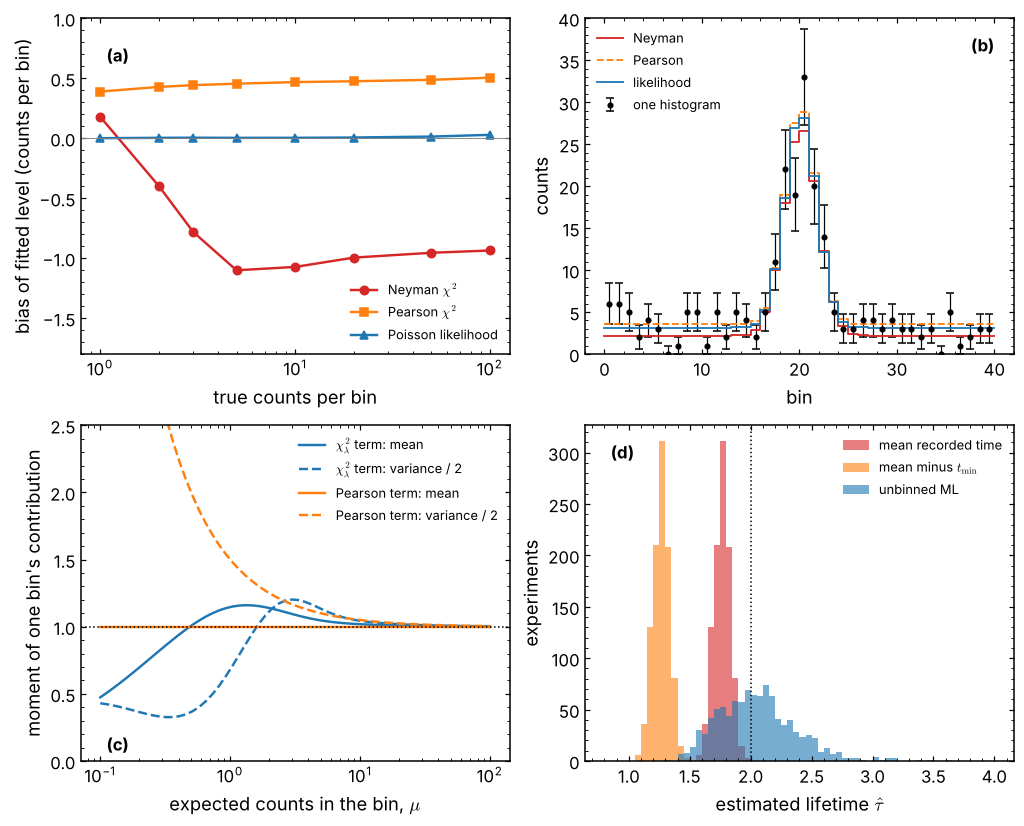

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
ax.semilogx(mus, bias["Neyman"], "o-", color="C3", label="Neyman $\\chi^2$")
ax.semilogx(mus, bias["Pearson"], "s-", color="C1", label="Pearson $\\chi^2$")
ax.semilogx(mus, bias["likelihood"], "^-", color="C0", label="Poisson likelihood")
ax.axhline(0, color="0.5", lw=0.6)
ax.set_xlabel("true counts per bin"); ax.set_ylabel("bias of fitted level (counts per bin)")
ax.set_ylim(-1.8, 1.0); ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(a)", x=0.06, y=0.92)

ax = axes[0, 1]
xc = edges[:-1] + 0.5
ax.errorbar(xc, n_example, np.sqrt(np.maximum(n_example, 1)), fmt="o", ms=3, color="k", lw=0.8, label="one histogram")
for k, c, ls in (("Neyman", "C3", "-"), ("Pearson", "C1", "--"), ("likelihood", "C0", "-")):
    ax.step(edges, np.r_[mu_model(est[k][0]), mu_model(est[k][0])[-1]], where="post", color=c, ls=ls, lw=1.2, label=k)
ax.set_xlabel("bin"); ax.set_ylabel("counts")
ax.set_ylim(0, 40); ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.9)

ax = axes[1, 0]
ax.semilogx(mu_grid, moments["lambda"][:, 0], "C0", label=r"$\chi^2_\lambda$ term: mean")
ax.semilogx(mu_grid, moments["lambda"][:, 1] / 2, "C0--", label=r"$\chi^2_\lambda$ term: variance / 2")
ax.semilogx(mu_grid, moments["Pearson"][:, 0], "C1", label="Pearson term: mean")
ax.semilogx(mu_grid, moments["Pearson"][:, 1] / 2, "C1--", label="Pearson term: variance / 2")
ax.axhline(1, color="k", ls=":", lw=1)
ax.set_xlabel(r"expected counts in the bin, $\mu$"); ax.set_ylabel("moment of one bin's contribution")
ax.set_ylim(0, 2.5); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(c)", x=0.06, y=0.08)

ax = axes[1, 1]
bins = np.linspace(0.8, 4.0, 65)
ax.hist(rows[:, 0], bins, color="C3", alpha=0.6, label="mean recorded time")
ax.hist(rows[:, 1], bins, color="C1", alpha=0.6, label=r"mean minus $t_\mathrm{min}$")
ax.hist(rows[:, 2], bins, color="C0", alpha=0.6, label="unbinned ML")
ax.axvline(tau_true, color="k", ls=":", lw=1)
ax.set_xlabel(r"estimated lifetime $\hat\tau$"); ax.set_ylabel("experiments")
ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.06)
plt.show()

**(a)** Bias of a constant level fitted to 20 bins, against the true level.
**(b)** One of the simulated histograms with the three fits; the $\chi^2$ fits
differ from the likelihood fit mainly in the background. **(c)** Mean and
variance (halved) of one bin's contribution to the two goodness-of-fit
statistics; for a $\chi^2$ variable both would equal 1 (dotted). **(d)**
Lifetime estimates from 1000 experiments with a finite observation window;
dotted: the true lifetime.

## Summary

* For histograms, Neyman's $\chi^2$ (weights from the data) biases a fitted
  level by about $-1$ count per bin, Pearson's (weights from the model) by
  about $+\tfrac12$. The bias does not shrink relative to the statistical
  uncertainty as the counts grow.
* Fit counts by the Poisson likelihood, conveniently as $\chi^2_\lambda$ with
  deviance residuals; uncertainties from the Fisher information or from
  $\Delta\chi^2_\lambda = 1$.
* With a few counts per bin, $\chi^2_\lambda$ at the minimum overstates the
  misfit; use Pearson's statistic at the likelihood estimates, or calibrate
  by simulation.
* With individual events, use the unbinned likelihood. It handles windows,
  efficiencies and resolution naturally, where simple averages are biased.

## References

* S. Baker and R. D. Cousins, "Clarification of the use of chi-square and
  likelihood functions in fits to histograms", *Nucl. Instrum. Methods*
  **221**, 437 (1984).
* W. Cash, "Parameter estimation in astronomy through application of the
  likelihood ratio", *Astrophys. J.* **228**, 939 (1979).
* G. Cowan, *Statistical Data Analysis* (Oxford University Press, 1998).
* F. James, *Statistical Methods in Experimental Physics*, 2nd ed. (World
  Scientific, 2006).

## Exercises

1. Show that minimising Neyman's $\chi^2$ for a constant level gives the
   harmonic mean of the counts, and Pearson's the root-mean-square. Expand
   both for large $\mu$ to obtain the biases of $-1$ and $+\tfrac12$.
2. Show that $\chi^2_\lambda$ and $-2\ln L$ differ by a term that does not
   depend on the parameters.
3. Repeat the peak fit with a background of 30 counts per bin. How do the
   relative biases of the background change?
4. Implement the parametric bootstrap for the goodness of fit of
   Section 15.2 and compare its p-value with the nominal one for a single
   histogram.
5. In the lifetime example, bin the decay times into 10, 30 and 100 bins
   and fit by the Poisson likelihood. How do estimate and uncertainty
   compare with the unbinned fit?

---

**Previous:** [14. Nonlinear least squares](14_nonlinear_least_squares.ipynb) &nbsp;·&nbsp; **Next:** [16. Rules of thumb, tested](16_rules_of_thumb_tested.ipynb)